In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))


In [3]:
from __future__ import annotations

from pathlib import Path
from typing import Any, TypedDict, Callable, Literal, cast
from audioml.shared.data import SharedCollection
import librosa
import pandas as pd

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.optim as optim
import torch
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import numpy as np
from functools import partial

tqdm.pandas()

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Dataset
Audio is preprocessed on another machine, so we need to load them on this machine for training.

In [5]:
prefix = Path("../data")

In [7]:
with open(prefix.joinpath("labels.csv"), "r") as f:
    labels: pd.DataFrame = pd.read_csv(f)

Standardise path into prefix/raw/Type/file or prefix/processed/Type/file (discrepancy caused by moving dataset around machine)

In [8]:
labels.source_file = labels.source_file.progress_apply(lambda x: prefix.joinpath(Path("raw", *Path(x).parts[2:])))
labels.processed_file = labels.processed_file.progress_apply(
    lambda x: prefix.joinpath(Path("processed", *Path(x).parts[1:])))

  0%|          | 0/5940 [00:00<?, ?it/s]

  0%|          | 0/5940 [00:00<?, ?it/s]

In [9]:
labels[:3]

,source_file,processed_file,fire_seeker_gain,fire_seeker_low,fire_seeker_mid,fire_seeker_treble
0,../data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,../data/processed/Gretsch/Gretsch_F_open_122_I...,0.415212,0.382531,0.889004,0.717846
1,../data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,../data/processed/Gretsch/Gretsch_F_open_122_I...,0.828639,0.576327,0.966072,0.016324
2,../data/raw/Gretsch/Gretsch_F_open_122_ID1_4.wav,../data/processed/Gretsch/Gretsch_F_open_122_I...,0.093933,0.267912,0.440884,0.377729


Filter out missing file

In [10]:
def filter_existing(row: pd.Series) -> bool:
    if row.processed_file.exists():
        return True
    else:
        print(f"\033[31mProcessed file {row.processed_file} not found, skipping\033[0m")
        return False

In [11]:
def calc_length(row: pd.Series) -> pd.Series:
    x, sr = librosa.load(row.processed_file)
    row["length"] = len(x)
    return row

In [12]:
tqdm.pandas(desc="Filtering")
filtered = labels[labels.progress_apply(filter_existing, axis=1)]
tqdm.pandas(desc="Calculating sample length")
filtered = filtered.progress_apply(calc_length, axis=1)

Filtering:   0%|          | 0/5940 [00:00<?, ?it/s]

Processed file ../data/processed/Gretsch/Gretsch_F_open_122_ID1_4_1.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_F_open_122_ID1_4_2.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_F_open_122_ID1_4_3.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_Am_open_222_ID1_10_1.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_Am_open_222_ID1_10_2.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_Am_open_222_ID1_10_3.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_B_open_022_ID1_6_1.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_B_open_022_ID1_6_2.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_B_open_022_ID1_6_3.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_Cm_open_122_ID1_9_1.wav not found, skipping
Processed file ../data/processed/Gretsch/Gretsch_Cm_open_122_ID1_9_2.wav 

Calculating sample length:   0%|          | 0/662 [00:00<?, ?it/s]

## Boilerplates
Scaffolding to share code across different implementations, for the ease of experimenting with various setting, e.g. different features or different models

In [ ]:
from audioml.shared.misc import to_tensor

def extract_X_y(df: pd.DataFrame, *, X_labels: list[str],
                x_mapper: Callable[[pd.DataFrame], np.ndarray] = lambda x: x.to_numpy()) -> \
        tuple[np.ndarray, np.ndarray]:
    return x_mapper(df[X_labels]), df[
        ["fire_seeker_gain", "fire_seeker_low", "fire_seeker_mid", "fire_seeker_treble"]].to_numpy()


class Dataset[T: torch.Tensor | np.ndarray](TypedDict):
    X_train: T
    y_train: T
    X_val: T
    y_val: T
    X_test: T
    y_test: T

class Collection:
    def __init__(self, model: nn.Module,
                 loss: nn.modules.loss._Loss,
                 optimiser: Callable[[optim.optimizer.ParamsT], torch.optim.Optimizer],
                 scaler: StandardScaler):
        self.model = model.to(device)
        self.loss = loss.to(device)
        self.optimiser = optimiser(self.model.parameters())
        self.scaler = scaler

def to_shared_collection(c: Collection)->SharedCollection:
    return SharedCollection(c.model.to("cpu"), c.loss, c.scaler)
def to_device(dataset: Dataset[np.ndarray], d=device) -> Dataset[torch.Tensor]:
    return cast(Dataset, dict(
        map(lambda x: (x[0], to_tensor(x[1]).to(d)),
            dataset.items())))


def scale(dataset: Dataset[np.ndarray], scaler) -> Dataset[np.ndarray]:
    return Dataset(X_train=scaler.fit_transform(dataset["X_train"]), y_train=dataset["y_train"],
                   X_val=scaler.transform(dataset["X_val"]), y_val=dataset["y_val"],
                   X_test=scaler.transform(dataset["X_test"]), y_test=dataset["y_test"])


def split_dataset(X: np.ndarray, y: np.ndarray) -> Dataset[np.ndarray]:
    X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.2, random_state=0)
    X_val_unscaled, X_test_unscaled, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=0)
    return Dataset(X_train=X_train, y_train=y_train, X_val=X_val_unscaled, y_val=y_val, X_test=X_test_unscaled,
                   y_test=y_test)


def test_model(dataset: Dataset, c: Collection,
               sample: int | None = None, key: Literal["test", "val", "train"] = "test"):
    total = torch.tensor(0.0).to(device)
    n = len(dataset["X_" + key])
    tqdm.pandas(desc="Predicting")

    # slower than just throwing the entire tensor into model and loss, but makes writing the random sampling code easier
    for i in tqdm(range(n) if sample is None else np.random.choice(n, sample)):
        y_hat = c.model(dataset["X_" + key][i])
        l = c.loss(y_hat, dataset["y_" + key][i])
        print(f"y: {dataset["y_" + key][i]} ŷ: {y_hat} loss: {l}")
        total += l
    avg = total / n
    print(
        f"Average loss{" of entire dataset" if sample is not None else ""}: {avg if sample is None else c.loss(c.model(dataset["X_" + key]), dataset["y_" + key])}")


def train_model(c: Collection, dataset: Dataset[torch.Tensor],
                epochs: int) -> list[float]:
    loss_history = []
    c.model.train()
    for _ in (n := tqdm(range(epochs), desc="Training")):
        c.optimiser.zero_grad()
        output = c.model(dataset["X_train"])
        loss = c.loss(output, dataset["y_train"])
        loss.backward()
        c.optimiser.step()
        n.postfix = str(loss.item())
        loss_history.append(loss.item())
    return loss_history


def loss_history(hist):
    plt.title("Loss History")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.plot(hist)


## Naive implementation
For our first model, we'll only provide 3 features, root mean square, spectral centroid and zero crossing rate

In [12]:
from audioml.shared.feat_ext import root_mean_square, spectral_centroid, zero_crossing_rate


def calculate_naive_features(row: pd.Series) -> pd.Series:
    x, sr = librosa.load(row.processed_file)

    row["root_mean_square"] = root_mean_square(x)
    row["spectral_centroid"] = spectral_centroid(x, sr=sr)
    row["zero_crossing_rate"] = zero_crossing_rate(x)
    return row

In [13]:
tqdm.pandas(desc="Calculating Features")
naive_features = filtered.progress_apply(calculate_naive_features, axis=1)

Calculating Features:   0%|          | 0/4673 [00:00<?, ?it/s]

In [14]:
naive_X, naive_y = extract_X_y(naive_features, X_labels=["root_mean_square", "spectral_centroid", "zero_crossing_rate"])
naive_scaler = StandardScaler()
naive_dataset: Dataset = to_device(scale(split_dataset(naive_X, naive_y), naive_scaler))

We'll be using a basic MLP with only 4 layers (2 hidden) and all activation will be using RELU. Input layer will have our 3 only features, then it widens up to 70 then narrow back down until the output is of size 3 (the 3 parameters we're trying to predict).


In [16]:

from audioml.shared.model import NaiveModel

In [17]:
naive = Collection(
    NaiveModel(),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9),
    naive_scaler
)

naive_loss_history = train_model(naive, naive_dataset, 50000)

Training:   0%|          | 0/50000 [00:00<?, ?it/s]

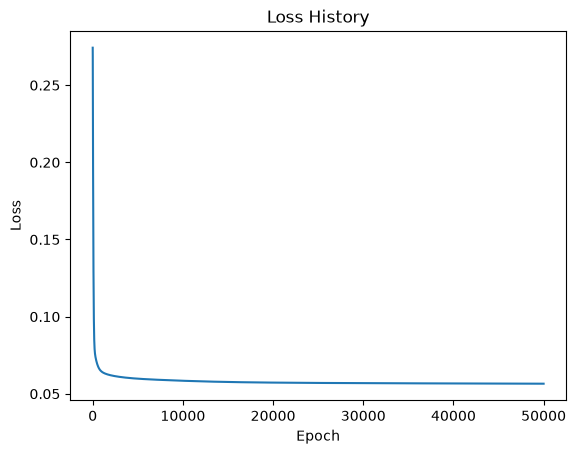

In [18]:
loss_history(naive_loss_history)

In [19]:
test_model(naive_dataset, naive, key="train", sample=3)
test_model(naive_dataset, naive, sample=3)

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.5746, 0.5157, 0.7904, 0.3032], device='cuda:0') ŷ: tensor([0.6603, 0.4710, 0.5129, 0.5859], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.04156611114740372
y: tensor([0.5630, 0.2318, 0.0331, 0.0811], device='cuda:0') ŷ: tensor([0.5650, 0.5273, 0.2809, 0.1396], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.038033753633499146
y: tensor([0.9883, 0.5304, 0.5985, 0.7547], device='cuda:0') ŷ: tensor([0.8746, 0.5044, 0.4061, 0.7224], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.012912005186080933
Average loss of entire dataset: 0.05653830245137215


  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.6424, 0.5420, 0.1946, 0.8009], device='cuda:0') ŷ: tensor([0.6386, 0.5353, 0.2725, 0.6093], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.010717784985899925
y: tensor([0.1218, 0.3909, 0.1325, 0.7078], device='cuda:0') ŷ: tensor([0.2404, 0.5149, 0.4121, 0.5902], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.03036346472799778
y: tensor([0.2671, 0.5164, 0.8161, 0.1545], device='cuda:0') ŷ: tensor([0.4278, 0.5755, 0.2866, 0.2413], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.0793139636516571
Average loss of entire dataset: 0.058807481080293655


The naive attempts did not preform well for test dataset (and it definitely did not generalise well). With equally terrible accuracy for both seen and unseen data, this is expected, as we only have 3 features and it is very unlikely to be enough.

## Second attempt
For out second attempts, instead of calculating our features for the entire samples, we take slices of out sample and calculate features on them, hopefully this gives more information that the model need to preform better. Here, I kept the window and frame length as librosa's default.

In [20]:
from librosa.feature import rms, spectral_centroid, zero_crossing_rate


def calculate_windowed_naive_features() -> Callable[[pd.Series], pd.Series]:
    samples = min(filtered[
                      "length"])  # truncate out excess, most audio clip should be ~5 second, but with some very small variation that we can just chop out

    def _inner(row: pd.Series) -> pd.Series:
        x, sr = librosa.load(row.processed_file)
        x = x[:samples]
        S = np.abs(librosa.stft(x))
        row["root_mean_square"] = rms(S=S)[0]
        row["spectral_centroid"] = spectral_centroid(y=x, sr=sr)[0]
        row["zero_crossing_rate"] = zero_crossing_rate(x)[0]
        return row

    return _inner

In [21]:
tqdm.pandas(desc="Calculating Features")
windowed_naive_feature = filtered.progress_apply(calculate_windowed_naive_features(), axis=1)

Calculating Features:   0%|          | 0/4673 [00:00<?, ?it/s]

Machine learning model expects a flat 1D array as features, so we have to concatenate the three feature column containing ndarry each into a single ndarry.

In [22]:
def flatten(x: pd.DataFrame) -> np.ndarray:
    x = x.apply(
        lambda row: np.concatenate([row["root_mean_square"], row["spectral_centroid"], row["zero_crossing_rate"]],
                                   dtype=np.float32), axis=1)
    return np.vstack(x.to_numpy()).astype(np.float32)

In [23]:
windowed_naive_X, windowed_naive_y = extract_X_y(windowed_naive_feature,
                                                 X_labels=["root_mean_square", "spectral_centroid",
                                                           "zero_crossing_rate"], x_mapper=flatten)
windowed_naive_dataset_scaler = StandardScaler()
windowed_naive_dataset = to_device(scale(split_dataset(windowed_naive_X, windowed_naive_y), windowed_naive_dataset_scaler))

I've decided to use the exact same model as before, but with a larger input layer to accommodate for all the features.

In [24]:
windowed_naive_old_neurons = Collection(
    NaiveModel(input_n=windowed_naive_X.shape[1]),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9),
    windowed_naive_dataset_scaler
)

windowed_naive_old_neurons_loss_history = train_model(windowed_naive_old_neurons, windowed_naive_dataset, 50000)

Training:   0%|          | 0/50000 [00:00<?, ?it/s]

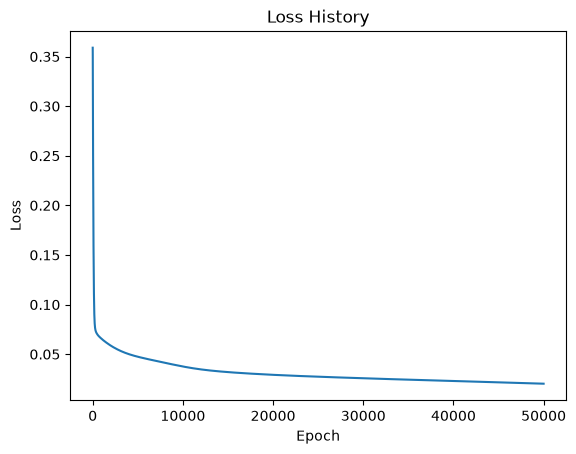

In [25]:
loss_history(windowed_naive_old_neurons_loss_history)

For comparison, I made a model with significantly more neuron on each hidden layer


In [26]:
windowed_naive_larger_model = Collection(
    NaiveModel(input_n=windowed_naive_X.shape[1], h1_n=1000, h2_n=500, h3_n=100),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9),
    windowed_naive_dataset_scaler
)

windowed_naive_larger_model_loss_history = train_model(windowed_naive_larger_model, windowed_naive_dataset, 50000)

Training:   0%|          | 0/50000 [00:00<?, ?it/s]

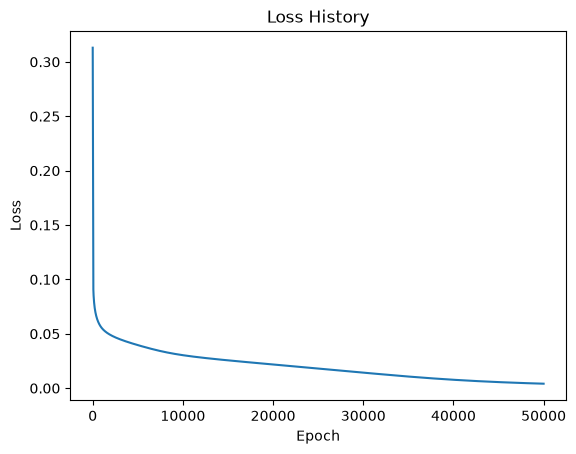

In [27]:
loss_history(windowed_naive_larger_model_loss_history)

In [28]:
test_model(windowed_naive_dataset, windowed_naive_old_neurons, key="train", sample=3)
test_model(windowed_naive_dataset, windowed_naive_old_neurons, key="val", sample=3)

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.2043, 0.0568, 0.1512, 0.6928], device='cuda:0') ŷ: tensor([0.1751, 0.2524, 0.2154, 0.8421], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.01638597995042801
y: tensor([0.9701, 0.5034, 0.5528, 0.6825], device='cuda:0') ŷ: tensor([0.9551, 0.6972, 0.6309, 0.7209], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.011342947371304035
y: tensor([0.9095, 0.6604, 0.9819, 0.1930], device='cuda:0') ŷ: tensor([0.9155, 0.3893, 0.9684, 0.1999], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.018452243879437447
Average loss of entire dataset: 0.020277228206396103


  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.3506, 0.2557, 0.8979, 0.0163], device='cuda:0') ŷ: tensor([0.4103, 0.5047, 0.6388, 0.1871], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.040466371923685074
y: tensor([0.6804, 0.2403, 0.2742, 0.6121], device='cuda:0') ŷ: tensor([0.6569, 0.6477, 0.3595, 0.7031], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.045522935688495636
y: tensor([0.5258, 0.9988, 0.2631, 0.3141], device='cuda:0') ŷ: tensor([0.5626, 0.7058, 0.2573, 0.2394], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.02320910058915615
Average loss of entire dataset: 0.0333716981112957


In [29]:
test_model(windowed_naive_dataset, windowed_naive_larger_model, key="train", sample=3)
test_model(windowed_naive_dataset, windowed_naive_larger_model, key="val", sample=3)

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.2850, 0.2107, 0.7950, 0.3444], device='cuda:0') ŷ: tensor([0.2767, 0.1952, 0.8033, 0.3200], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.00024391199985984713
y: tensor([0.3573, 0.6598, 0.1285, 0.4500], device='cuda:0') ŷ: tensor([0.3925, 0.7055, 0.2123, 0.4943], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.0030783512629568577
y: tensor([0.5181, 0.2338, 0.4099, 0.5947], device='cuda:0') ŷ: tensor([0.5124, 0.3635, 0.4211, 0.6544], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.005139918532222509
Average loss of entire dataset: 0.004125244915485382


  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.9723, 0.4959, 0.6563, 0.7751], device='cuda:0') ŷ: tensor([1.0758, 0.2826, 0.4174, 0.8360], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.029253367334604263
y: tensor([0.1263, 0.5288, 0.5392, 0.8458], device='cuda:0') ŷ: tensor([0.0853, 0.4729, 0.5971, 0.8610], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.0020982520654797554
y: tensor([0.3727, 0.4132, 0.8585, 0.7453], device='cuda:0') ŷ: tensor([0.5063, 0.4261, 0.4700, 0.3627], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.0788155049085617
Average loss of entire dataset: 0.03464135155081749


While both model preformed quite well at the training data, the one with same neurons count as our naive model preforms worse at training data compared to the larger model. On the validation dataset, both preform quite terribly, but the larger model produce slightly smaller loss.

Understandably, now that we slice and sample chunk of the sample, and have more than 3 features, the machine learning model have a lot more information to work with compared to the naive model. This is likely why the new model is so much better at training dataset than naive, but it seems like it did not generalise well, perhaps it simply learned to distinguish between all the audio sample in training dataset.

In [30]:
print(f"{windowed_naive_X.shape[1]} features")
print(f"{windowed_naive_feature.spectral_centroid.iloc[0].shape[0]} value per features")

636 features
212 value per features


And in hindsight, I feel like a total of 636 features was excessive, I probably should've diverted from librosa's default, ~5 features per second and 25 features for an entire clips sound more reasonable.

## (A more) Sensible classical model
Instead of keeping all features over time, we've decided to calculate the mean _and the variance_ as features

In [31]:

from audioml.shared.features import calculate_classical_features

In [ ]:
tqdm.pandas(desc="Calculating Features")
classical_feature = filtered.progress_apply(calculate_classical_features, axis=1)

In [34]:
def flatten(x: pd.DataFrame) -> np.ndarray:
    x = x.apply(lambda row: row.to_numpy(), axis=1)
    # pyrefly: ignore[no-matching-overload]
    return np.vstack(x.to_numpy()).astype(np.float32)

In [35]:
classical_X, classical_y = extract_X_y(classical_feature,
                                       X_labels=["root_mean_square_mean", "root_mean_square_variance",
                                                 "spectral_centroid_mean", "spectral_centroid_variance",
                                                 "zero_crossing_rate_mean", "zero_crossing_rate_variance"],
                                       x_mapper=flatten)
classical_scaler = StandardScaler()
classical_dataset = to_device(scale(split_dataset(classical_X, classical_y), classical_scaler))

In [36]:
classical = Collection(
    NaiveModel(input_n=classical_X.shape[1]),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9),
    classical_scaler
)

classical_loss_history = train_model(classical, classical_dataset, 50000)

Training:   0%|          | 0/50000 [00:00<?, ?it/s]

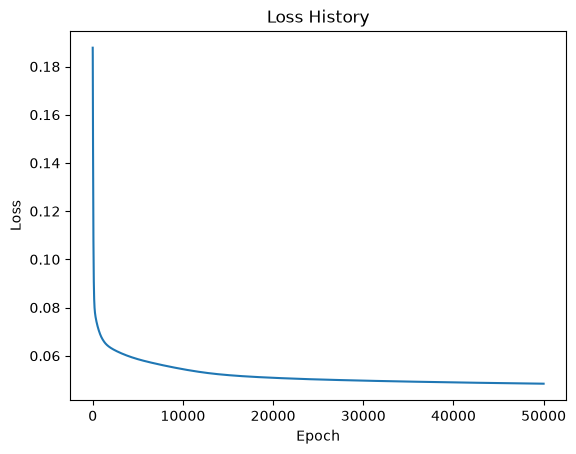

In [37]:
loss_history(classical_loss_history)

In [38]:
test_model(classical_dataset, classical, key="train", sample=3)
test_model(classical_dataset, classical, key="test", sample=3)

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.9688, 0.6927, 0.9555, 0.6938], device='cuda:0') ŷ: tensor([0.9450, 0.5293, 0.7051, 0.5875], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.025314439088106155
y: tensor([0.3303, 0.0582, 0.7236, 0.3165], device='cuda:0') ŷ: tensor([0.3646, 0.4359, 0.6228, 0.4399], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.04230901971459389
y: tensor([0.7225, 0.3999, 0.1049, 0.9856], device='cuda:0') ŷ: tensor([0.8127, 0.4828, 0.2668, 0.6659], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.035842739045619965
Average loss of entire dataset: 0.04842081293463707


  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.1540, 0.8588, 0.8866, 0.7961], device='cuda:0') ŷ: tensor([0.3588, 0.5982, 0.2266, 0.2462], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.2119501531124115
y: tensor([0.3417, 0.7742, 0.6567, 0.7074], device='cuda:0') ŷ: tensor([0.5105, 0.5750, 0.3626, 0.4500], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.05523143708705902
y: tensor([0.1817, 0.1868, 0.3563, 0.3496], device='cuda:0') ŷ: tensor([0.1322, 0.5147, 0.5366, 0.4366], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.03750225901603699
Average loss of entire dataset: 0.05195872485637665


In [39]:
def save_result(c: Collection, df: pd.DataFrame)->pd.DataFrame:
    def _inner(row):
        # ["fire_seeker_gain", "fire_seeker_low", "fire_seeker_mid", "fire_seeker_treble"]]

        a = calculate_classical_features(row)[["root_mean_square_mean", "root_mean_square_variance",
                                                 "spectral_centroid_mean", "spectral_centroid_variance",
                                                 "zero_crossing_rate_mean",
                                                 "zero_crossing_rate_variance"]].to_numpy().reshape(1, -1)
        y_hat = c.model(to_tensor(classical_scaler.transform(a)).to(device))[0]

        row["fire_seeker_gain_pred"] = y_hat[0]
        row["fire_seeker_low_pred"] = y_hat[1]
        row["fire_seeker_mid_pred"] = y_hat[2]
        row["fire_seeker_treble_pred"] = y_hat[3]

        return row

    return df.progress_apply(_inner, axis=1)

Then I dumped the model and scaler for use on the machine with VST installed, so we could experiemnt and visalise what was happening.

In [40]:
test = save_result(classical, filtered)
def conversion(x: Any):
    if isinstance(x, Path):
        return str(x)
    elif isinstance(x, torch.Tensor):
        return x.tolist()
    else:
        raise Exception(f"Do not know how to convert {type(x)} into something serialisable")

with open("../dump/classical.json", "w") as f:
    test.to_json(f, default_handler=conversion)

Predicting:   0%|          | 0/4673 [00:00<?, ?it/s]

Then I dumped the model and scaler for use on the machine with VST installed, so we could experiemnt and visalise what was happening.

In [41]:
from pickle import dump
with open("../dump/classical.pickel", "wb") as f:
    dump(to_shared_collection(classical), f)

The model predicted all input at maximum when gain is high, which made us think that out lack of audio volume normalisation could be causing issue.

## Normalisation

In [42]:
from audioml.shared.features import calculate_normalised_classical_features

In [43]:
tqdm.pandas(desc="Calculating Features")
normalised_classical_feature = filtered.progress_apply(calculate_normalised_classical_features, axis=1)

Calculating Features:   0%|          | 0/4673 [00:00<?, ?it/s]

In [44]:
normalised_classical_X, normalised_classical_y = extract_X_y(normalised_classical_feature,
                                       X_labels=["root_mean_square_mean", "root_mean_square_variance",
                                                 "spectral_centroid_mean", "spectral_centroid_variance",
                                                 "zero_crossing_rate_mean", "zero_crossing_rate_variance"],
                                       x_mapper=flatten)
normalised_classical_scaler = StandardScaler()
normalised_classical_dataset = to_device(scale(split_dataset(normalised_classical_X, normalised_classical_y), normalised_classical_scaler))

In [46]:
normalised_classical = Collection(
    NaiveModel(input_n=normalised_classical_X.shape[1]),
    nn.MSELoss(),
    partial(optim.SGD, lr=0.001, momentum=0.9),
    normalised_classical_scaler
)

normalised_classical_loss_history = train_model(normalised_classical, normalised_classical_dataset, 50000)

Training:   0%|          | 0/50000 [00:00<?, ?it/s]

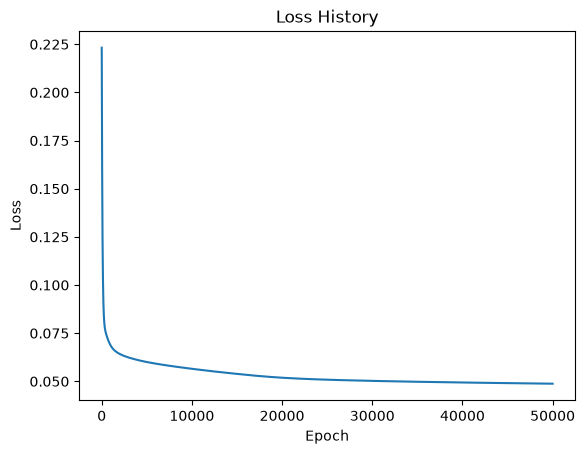

In [47]:
loss_history(normalised_classical_loss_history)

In [48]:
test_model(normalised_classical_dataset, normalised_classical, key="train", sample=3)
test_model(normalised_classical_dataset, normalised_classical, key="test", sample=3)

  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.0782, 0.6679, 0.6797, 0.7620], device='cuda:0') ŷ: tensor([0.0580, 0.4871, 0.5393, 0.6118], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.018848562613129616
y: tensor([0.6611, 0.6103, 0.8633, 0.4585], device='cuda:0') ŷ: tensor([0.8284, 0.5329, 0.6462, 0.2188], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.03464992344379425
y: tensor([0.9780, 0.9390, 0.5572, 0.2043], device='cuda:0') ŷ: tensor([0.4722, 0.4469, 0.4311, 0.6497], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.1780768632888794
Average loss of entire dataset: 0.04877886921167374


  0%|          | 0/3 [00:00<?, ?it/s]

y: tensor([0.8521, 0.9921, 0.1231, 0.5706], device='cuda:0') ŷ: tensor([0.6880, 0.5386, 0.3896, 0.5291], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.0763387680053711
y: tensor([0.5668, 0.1594, 0.1679, 0.7102], device='cuda:0') ŷ: tensor([0.6946, 0.5051, 0.2999, 0.7067], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.03831151872873306
y: tensor([0.7632, 0.1944, 0.0242, 0.4576], device='cuda:0') ŷ: tensor([0.6519, 0.4472, 0.5471, 0.5209], device='cuda:0',
       grad_fn=<UnsafeViewBackward0>) loss: 0.08841487765312195
Average loss of entire dataset: 0.05169381573796272


In [ ]:
with open("../dump/normalised_classical.pickel", "wb") as f:
    dump(to_shared_collection(normalised_classical), f)

In [49]:
normalised_classical_dataset["X_test"]

tensor([[ 1.1753,  0.8006, -1.3118, -0.8077, -1.4184, -0.6901],
        [-1.0891, -1.0235,  0.1410,  1.7005,  0.8232,  2.2726],
        [-0.7149, -0.7582,  0.7086, -0.5350,  1.0427, -0.4275],
        ...,
        [ 1.0788,  1.0900, -0.3281, -0.1931, -0.5156, -0.1281],
        [-0.0380,  0.0822,  0.6702,  0.1268,  0.4830, -0.3357],
        [ 0.5503,  0.6715,  0.1229,  0.1880, -0.0038, -0.0946]],
       device='cuda:0')

## More features

# Convolutional Neural Network

In [14]:
from audioml.shared.mfcc import calc_mfcc

## create features and scale


our feature for our CNN is the mel frequnecy cepstral coefficents (MFCC)

this is a 2d array with time on the x-axis and frequency on the y-axis

we can spceify the dimensions of this 2d array, with a lower resolution being more computationally efficient, but may lead to lower accuracy. 

the default is 26x99

values are measured in power 

In [19]:
HEIGHT = 26 # This number will come up again when calculating
           # the number of inputs to layers in our network
def calculate_cnn_features(row: pd.Series) -> np.ndarray:
    x, sr = librosa.load(row.processed_file)
    mfcc = calc_mfcc(x, sr, width=99, height=HEIGHT)
    return mfcc

In [ ]:
tqdm.pandas(desc="calculating features...")
cnn_features = filtered.progress_apply(calculate_cnn_features, axis=1)

In [ ]:
cnn_X, cnn_y = extract_X_y(cnn_features, X_labels=["MFCC"])
cnn_scaler = StandardScaler()
cnn_dataset = Dataset = to_device(scale(split_dataset(cnn_X, cnn_y), cnn_scaler))


### CNN Architecture

our CNN will have 4 convolutional layers (nn.Conv2d), with the following specifications:

**All layers:** 
- 3x3 filter
- 1x1 stride
- activation function: Relu
- padding mode "same"
- bias = True

*Layer 1:* 
- in_channels: 1 (our original image has 1 greyscale channel)
- out_channels: 16 

*Layer 2:*
- in channels:16
- out_channels: 32

*Layer 3:*
- in channels:32
- out_channels: 64

*Layer 4:*
- in channels:64
- out_channels: 128

Next is the pooling layer. We use a Global Average Pooling (nn.AdaptiveAvgPool2d) layer to preserve resolution in frequency.

*Layer 5: GAP POOLING LAYER*:
- output_size: 1

Next is a dropout layer, this sets a random number of weights to 0 to help with overfitting issues

*Layer 6: Dropout Layer*
- propability: 0.5

*Layer 7: Flattening layer*

Now that we have a single vector containg all the information our convolutional layers learned, we can use fully connected layers to transform this into our final model predictions

*Layer 8: Dense layer*

*Layer 8: Dense layer*





In [ ]:
cnn_model = nn.Sequential(
    nn.Conv2d(1, 16, (3, 9), 1, "same", bias=True), # first layer uses (3,9) sized filter, since temporal inforamtion is not that important and only leads to higher compute times
    nn.ReLU(),
    nn.Conv2d(16, 32, (3, 3), 1, "same", bias=True),
    nn.ReLU(),
    nn.Conv2d(32, 64, (3, 3), 1, "same", bias=True),
    nn.ReLU(),
    nn.Conv2d(64, 128, (3, 3), 1, "same", bias=True),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((None,1)),
    nn.Dropout(0.2),
    nn.modules.flatten.Flatten(),
    nn.Linear(128 * HEIGHT, 64),
    nn.Linear(64, 4),
    nn.Sigmoid()
    )


In [ ]:
cnn = Collection(
    cnn_model,
    nn.MSELoss(),
    optim.Adam(cnn_model.parameters(), lr=0.001),
    cnn_scaler
)

cnn_loss_history = train_model(cnn, cnn_dataset, 50)

In [ ]:
loss_history(cnn_loss_history)